# Brain Tumour Segmentation with U-Net (ResNet34 Encoder)

This notebook trains a deep learning model to **segment brain tumours in MRI scans**. For every MRI image, the model outputs a pixel-level mask marking exactly where the tumour is.

**Approach at a glance**

| Component | Choice |
|---|---|
| Task | Binary semantic segmentation (tumour vs. background) |
| Dataset | Brain Tumor Segmentation (Kaggle, `nikhilroxtomar/brain-tumor-segmentation`): 3,064 MRI images with binary masks |
| Model | U-Net with a ResNet34 encoder pretrained on ImageNet (`segmentation_models_pytorch`) |
| Loss | 0.5 × Binary Cross-Entropy + 0.5 × Dice Loss |
| Optimiser | AdamW (lr = 1e-3) with ReduceLROnPlateau |
| Metric | Intersection over Union (IoU / Jaccard Index) |

**Workflow:** install libraries → download data → build dataset and augmentations → split train/validation → exploratory data analysis → define model, loss and metrics → train and validate → visualise predictions.

## 1. Install Dependencies

Installs the four libraries this project relies on, with **pinned versions** so the notebook behaves the same every time it is run:

- **segmentation-models-pytorch (smp):** ready-made segmentation architectures such as U-Net, with pretrained encoders.
- **timm:** a library of image backbones that smp uses for its encoders.
- **albumentations:** fast image augmentation that transforms an image and its mask together, so they stay aligned.
- **torchmetrics:** standard, GPU-friendly implementations of evaluation metrics such as IoU.

The `-q` flag keeps the installation output quiet.

In [50]:
!pip install -q segmentation-models-pytorch==0.3.1
!pip install -q timm==0.4.12
!pip install -q albumentations==1.3.0
!pip install -q torchmetrics==0.11.4

## 2. Imports and Setup

Imports every library used in the notebook and prepares the runtime.

- **Reproducibility:** fixing the random seed for Python, NumPy and PyTorch (including all GPUs) makes data splits, augmentations and weight initialisation repeatable, so results can be reproduced.
- **Device selection:** uses the GPU (`cuda`) if one is available, otherwise the CPU. Training a U-Net on a CPU is very slow, so in Colab enable a GPU via *Runtime → Change runtime type*.

In [51]:
import os, random, math, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF

import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
import torchmetrics

#reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
  torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device: ", DEVICE)

Device:  cuda


## 3. Download the Dataset from Kaggle

### 3.1 Upload the Kaggle API key

Opens a file picker in Colab so you can upload `kaggle.json`, which holds your Kaggle username and API key. The Kaggle command-line tool needs this file to download datasets on your behalf.

In [52]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle (1).json


{'kaggle (1).json': b'{"username":"rajaaqeeltariq","key":"KGAT_efa8102f8f07f1985744c84ad1cd758a"}\r\n'}

### 3.2 Configure Kaggle credentials

Moves `kaggle.json` into `/root/.kaggle/`, where the Kaggle CLI looks for it. `chmod 600` makes the file readable only by the owner. Kaggle warns about (or refuses) key files that other users could read, since the file contains a secret.

In [53]:
os.makedirs('/root/.kaggle', exist_ok=True)
!cp kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

### 3.3 Download the dataset

Downloads the **Brain Tumor Segmentation** dataset as a zip file. It contains MRI brain images and a matching binary mask for each one, where white pixels mark the tumour.

In [54]:
!kaggle datasets download -d nikhilroxtomar/brain-tumor-segmentation

Dataset URL: https://www.kaggle.com/datasets/nikhilroxtomar/brain-tumor-segmentation
License(s): unknown
brain-tumor-segmentation.zip: Skipping, found more recently modified local copy (use --force to force download)


### 3.4 Extract the dataset

Unzips the archive into `/content/Dataset`. The `-q` flag hides the long list of extracted file names.

*Note:* `mkdir` creates `/content/dataset` (lowercase), but the data is unzipped into `/content/Dataset` (capital D). `unzip` creates the folder itself, so this works, but the `mkdir` line is effectively unused.

In [55]:
!mkdir -p /content/dataset
!unzip -q brain-tumor-segmentation.zip -d /content/Dataset

replace /content/Dataset/images/1.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace /content/Dataset/images/10.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/Dataset/images/100.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: A


### 3.5 Verify the folder structure

Points to the `images/` and `masks/` folders and checks that both exist. It also grabs a few sample file paths as a quick sanity check before going further. Both checks should print `True`.

In [56]:
DATA_ROOT = Path("/content/Dataset")

images_dir = DATA_ROOT / 'images'
masks_dir = DATA_ROOT /'masks'

print("Images exists: ", images_dir.exists())
print("Masks exists: ", masks_dir.exists())

sample_images = list(images_dir.glob("*"))[:6]
print("Sample images count:", len(sample_images))

Images exists:  True
Masks exists:  True
Sample images count: 6


## 4. Dataset Class and Transforms

Defines how individual samples are loaded and how images are augmented.

**`BrainTumorSegDataset`** is a PyTorch `Dataset` that, for a given index:
1. Loads the MRI image as RGB and the mask as grayscale.
2. **Binarises the mask** (`> 127` → 1, otherwise 0), so every pixel is either tumour or background.
3. Applies the transforms to the image and mask *together*, so a flip or rotation affects both identically.
4. Returns the image tensor and a mask tensor of shape `(1, H, W)`.

**Transforms**
- `train_transform` resizes to 256×256 and adds **augmentation**: horizontal/vertical flips, 90° rotations, small shifts/scales/rotations, and brightness/contrast changes. Augmentation shows the model varied versions of each image, which reduces overfitting on a relatively small dataset.
- `valid_transform` only resizes and normalises. Validation images are left unaugmented so the evaluation reflects real, unaltered data.
- `Normalize()` scales pixel values using ImageNet statistics, matching what the pretrained encoder expects. `ToTensorV2()` converts the arrays into PyTorch tensors.

*Note:* this first version of the class refers to `augmentations` instead of `augmented`, which would raise an error. The class is redefined with the fix in the training section below.

In [57]:
class BrainTumorSegDataset(Dataset):
  def __init__(self, image_paths, mask_path, transforms=None):
    self.image_paths = image_paths
    self.mask_path = mask_path
    self.transforms = transforms

  def __len__(self):
    return len(self.image_paths)

  def __getitem__(self, idx):
    img = np.array(Image.open(self.image_paths[idx]).convert("RGB"))
    mask = np.array(Image.open(self.mask_path[idx]).convert("L"))
    mask = (mask > 127).astype("float32")
    if self.transforms:
      augmented = self.transforms(image=img, mask=mask)
      img = augmentations["image"]
      mask = augmentations["mask"].unsqueeze(0)
    else:
      img = TF.to_tensor(img)
      mask = torch.tensor(mask).unsqueeze(0)
    return img, mask

train_transform = A.Compose([
    A.Resize(256,256),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15, p=0.5),
    A.RandomBrightnessContrast(p=0.4),
    A.Normalize(),
    ToTensorV2()
])
valid_transform = A.Compose([
    A.Resize(256,256),
    A.Normalize(),
    ToTensorV2()
])

## 5. Train/Validation Split and DataLoaders

Builds the training and validation sets.

1. **Pairs images with masks:** each mask is assumed to share its image's file name, so `masks_dir / img.name` gives the matching mask.
2. **Splits the data 85% / 15%** into training and validation sets with `train_test_split`. The fixed `random_state` keeps the split the same on every run.
3. **Wraps each split in a Dataset**: augmented transforms for training, plain transforms for validation.
4. **Creates DataLoaders** that feed batches of 8 images to the model. `shuffle=True` randomises training order every epoch, `num_workers=2` loads data in parallel, and `pin_memory=True` speeds up CPU-to-GPU transfer.

In [58]:
all_images = sorted(list(images_dir.glob("*")))
all_masks = [masks_dir / img.name for img in all_images]

from sklearn.model_selection import  train_test_split
train_imgs, val_imgs, train_masks, val_masks = train_test_split(
    all_images, all_masks, test_size=0.15, random_state=SEED)

train_ds = BrainTumorSegDataset(train_imgs, train_masks, transforms = train_transform)
val_ds = BrainTumorSegDataset(val_imgs, val_masks, transforms = valid_transform)

BATCH_SIZE = 8
train_loader = DataLoader(train_ds, batch_size = BATCH_SIZE, shuffle = True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size = BATCH_SIZE, shuffle = True, num_workers=2, pin_memory=True)

print("Train batch", len(train_loader), "val batches:", len(val_loader))

Train batch 326 val batches: 58


## 6. Exploratory Data Analysis (EDA)

### 6.1 Dataset statistics

Computes basic statistics to understand the data before modelling.

- Prints the total number of images and the train/validation sizes.
- For the first 200 masks, calculates the **tumour area ratio**: the fraction of pixels in each image that belong to the tumour.
- Plots a histogram (with a smoothed KDE curve) of these ratios and prints the mean tumour coverage.

**Why it matters:** tumours typically cover only a small percentage of each image, so the classes are heavily imbalanced (far more background pixels than tumour pixels). A model trained with plain cross-entropy could score well just by predicting background everywhere. This finding is the motivation for adding **Dice loss** later.

Total images: 3064
Train: 2604 | Val: 460


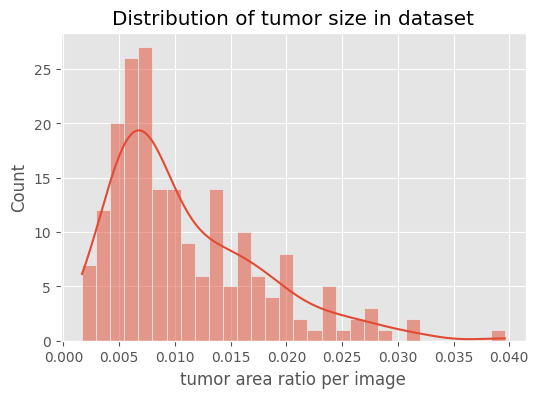

Mean tumor coverage:  1.10%


In [59]:
import cv2
import seaborn as sns
from PIL import Image
plt.style.use("ggplot")

print(f"Total images: {len(all_images)}")
print(f"Train: {len(train_imgs)} | Val: {len(val_imgs)}")

tumor_pixels = []
for m in all_masks[:200]:
    mask = np.array(Image.open(m).convert("L"))
    mask_bin = (mask > 127).astype(np.uint8)
    ratio = mask_bin.sum() / mask_bin.size
    tumor_pixels.append(ratio)

plt.figure(figsize=(6,4))
sns.histplot(tumor_pixels, bins=30, kde=True)
plt.xlabel("tumor area ratio per image")
plt.ylabel("Count")
plt.title("Distribution of tumor size in dataset")
plt.show()

print(f"Mean tumor coverage: {np.mean(tumor_pixels)*100: .2f}%")

### 6.2 Visualise random samples

Displays 6 random MRI scans next to the same scans with the tumour mask overlaid in red (40% transparency).

This visual check confirms that images and masks are correctly paired and aligned. It also gives a feel for how much tumours vary in **size, shape, location and contrast**, which is what the model has to learn to handle.

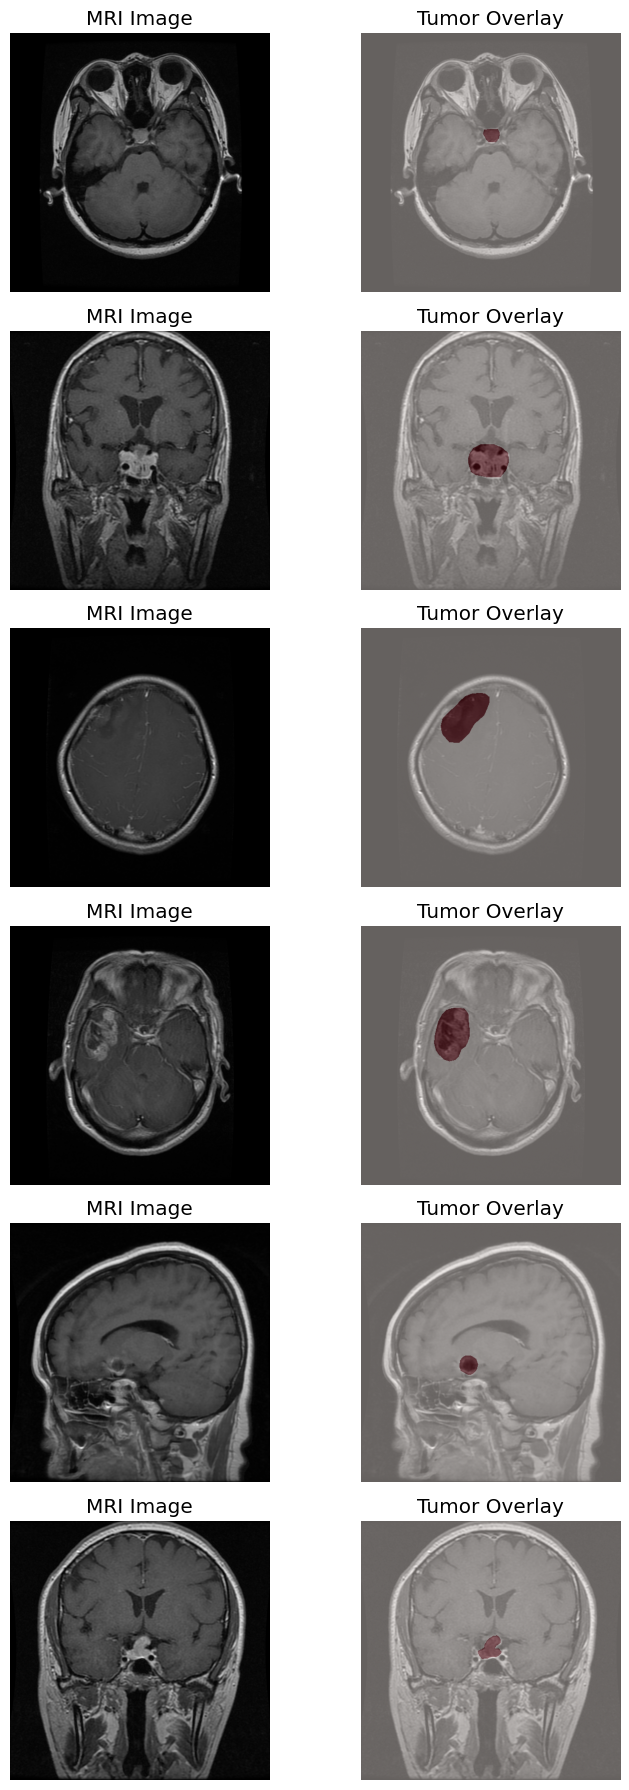

In [60]:
from PIL import Image

n_samples = 6
fig, axs = plt.subplots(n_samples, 2,  figsize=(8, 3*n_samples))
for i in range(n_samples):
    idx = random.randint(0, len(train_imgs)-1)
    img = np.array(Image.open(all_images[idx]).convert("RGB"))
    mask = np.array(Image.open(all_masks[idx]).convert("L"))
    mask_bin = (mask > 127).astype(np.uint8)
    axs[i, 0].imshow(img)
    axs[i, 0].set_title("MRI Image")
    axs[i, 1].axis("off")
    axs[i, 1].imshow(img)
    axs[i, 1].imshow(mask_bin, cmap="Reds", alpha=0.4)
    axs[i, 1].set_title("Tumor Overlay")
    axs[i, 0].axis("off")

plt.tight_layout()
plt.show()

## 7. Model, Loss Function, Optimiser and Metric

Sets up everything the model needs to learn.

**Model: U-Net with a ResNet34 encoder**
- **U-Net** has an *encoder* that progressively downsamples the image to capture *what* is in it, and a *decoder* that upsamples back to full resolution to recover *where* it is. **Skip connections** pass fine detail from encoder to decoder, which is what gives U-Net its sharp boundaries.
- The encoder is **ResNet34 pretrained on ImageNet** (transfer learning). It already knows general visual features like edges and textures, so it trains faster and generalises better than a network trained from scratch on 3,000 images.
- `classes=1` with `activation=None` means the model outputs one channel of raw scores (logits) per pixel. The sigmoid is applied later.

**Loss: BCE + Dice (50/50)**
- **Binary Cross-Entropy** judges each pixel independently and gives stable gradients.
- **Dice Loss** measures how well the predicted region *overlaps* the true region as a whole, which makes it robust to the class imbalance seen in the EDA.
- Combining the two gives stable training *and* good overlap with small tumours.

**Optimiser and scheduler**
- **AdamW** is Adam with properly decoupled weight decay, a strong default for fine-tuning.
- **ReduceLROnPlateau** halves the learning rate when validation loss stops improving for 3 epochs, which allows finer adjustments later in training.

**Metric:** **IoU (Jaccard Index)** = overlap ÷ union of the predicted and true masks. A score of 1.0 means a perfect match.

In [65]:
ENCODER = "resnet34"
ENCODER_WEIGHTS = "imagenet"
ACTIVATION = None

model = smp.Unet(
    encoder_name=ENCODER,
    encoder_weights=ENCODER_WEIGHTS,
    in_channels=3,
    classes=1,
    activation=ACTIVATION,
)
model.to(DEVICE)

class DiceLoss(nn.Module):
  def __init__(self, smooth=1e-6):
    super().__init__()
    self.smooth = smooth

  def forward(self, preds, targets):
    preds = torch.sigmoid(preds)
    preds = preds.view(preds.size(0), -1)
    targets = targets.view(targets.size(0), -1)
    intersection = (preds * targets).sum(1)
    union = preds.sum(1) + targets.sum(1)
    dice = (2 * intersection + self.smooth) / (union + self.smooth)
    return 1 - dice.mean()

bce = nn.BCEWithLogitsLoss()
dice = DiceLoss()

def loss_fn(preds, targets):
  return 0.5 * bce(preds, targets) + 0.5 * dice(preds, targets)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3
)

metric_iou = torchmetrics.JaccardIndex(task="binary").to(DEVICE)

## 8. Training and Validation

Contains the full training process.

**Corrected Dataset class:** the class is redefined to fix the variable-name bug in the earlier version, and to make sure every mask has the channel dimension `(1, H, W)` that the loss function expects. The datasets and DataLoaders are then rebuilt with this corrected class.

**`train_one_epoch`** runs one full pass over the training data. For each batch it makes predictions (forward pass), computes the loss, clears old gradients, backpropagates, and updates the weights. It returns the average loss per image.

**`validate_one_epoch`** evaluates the model without updating it (`model.eval()` and `torch.no_grad()` turn off dropout/batch-norm updates and gradient tracking). It converts predictions to probabilities with sigmoid, **thresholds at 0.5** to get binary masks, and computes the IoU for **each image individually** before averaging.

**Training loop:** runs for 30 epochs. After each epoch it records the training loss, validation loss and validation IoU, and passes the validation loss to the scheduler so it can lower the learning rate when progress stalls.

**Learning curves:** the final plots show loss and IoU over the epochs. Steadily falling losses, with validation loss tracking training loss, indicate the model is learning without overfitting. The rising IoU shows segmentation quality improving.

Epoch 1/30


Train:   0%|          | 0/326 [00:00<?, ?it/s]

Val:   0%|          | 0/58 [00:00<?, ?it/s]

Train Loss: 0.1710 | Val Loss: 0.1501 | Val IOU: 0.6502
Epoch 2/30


Train:   0%|          | 0/326 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79f488b5d260>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79f488b5d260>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

... (110 outputs left out)

Train Loss: 0.1129 | Val Loss: 0.1078 | Val IOU: 0.7300
Epoch 30/30


Train:   0%|          | 0/326 [00:00<?, ?it/s]

Val:   0%|          | 0/58 [00:00<?, ?it/s]

Train Loss: 0.1093 | Val Loss: 0.1076 | Val IOU: 0.7295


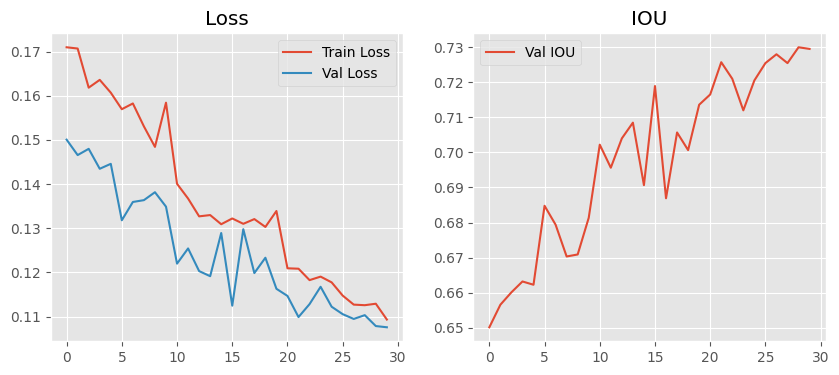

In [67]:
from tqdm.auto import tqdm

# Correcting the Dataset Class to ensure mask has channel dimension (1, H, W)
class BrainTumorSegDataset(Dataset):
  def __init__(self, image_paths, mask_path, transforms=None):
    self.image_paths = image_paths
    self.mask_path = mask_path
    self.transforms = transforms

  def __len__(self):
    return len(self.image_paths)

  def __getitem__(self, idx):
    img = np.array(Image.open(self.image_paths[idx]).convert("RGB"))
    mask = np.array(Image.open(self.mask_path[idx]).convert("L"))
    mask = (mask > 127).astype("float32")
    if self.transforms:
      augmented = self.transforms(image=img, mask=mask)
      img = augmented["image"]
      mask = augmented["mask"]
      if mask.ndim == 2:
        mask = mask.unsqueeze(0)
    else:
      img = TF.to_tensor(img)
      mask = torch.tensor(mask).unsqueeze(0)
    return img, mask

# Re-instantiating the datasets and loaders with the corrected class
train_ds = BrainTumorSegDataset(train_imgs, train_masks, transforms=train_transform)
val_ds = BrainTumorSegDataset(val_imgs, val_masks, transforms=valid_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)

def train_one_epoch(loader, model, optimizer):
  model.train()
  running_loss = 0.0
  for imgs, masks in tqdm(loader, desc="Train"):
    imgs = imgs.to(DEVICE)
    masks = masks.to(DEVICE)
    preds = model(imgs)
    loss = loss_fn(preds, masks)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    running_loss += loss.item() * imgs.size(0)
  return running_loss / len(loader.dataset)

def validate_one_epoch(loader, desc="Val"):
  model.eval()
  running_loss = 0.0
  iou_score = 0.0
  with torch.no_grad():
    for imgs, masks in tqdm(loader, desc=desc):
      imgs = imgs.to(DEVICE)
      masks = masks.to(DEVICE)
      preds = model(imgs)
      loss = loss_fn(preds, masks)
      running_loss += loss.item() * imgs.size(0)
      probs = torch.sigmoid(preds)
      preds_bin = (probs > 0.5).int()
      masks_int = masks.int()
      for p, t in zip(preds_bin, masks_int):
        i = metric_iou(p, t)
        iou_score += i.item()
    avg_loss = running_loss / len(loader.dataset)
    avg_iou = iou_score / len(loader.dataset)
  return avg_loss, avg_iou

EPOCHS = 30
history = {"train_loss": [], "val_loss": [], "val_iou": []}
for epoch in range(1, EPOCHS+1):
  print(f"Epoch {epoch}/{EPOCHS}")
  tr_loss = train_one_epoch(train_loader, model, optimizer)
  val_loss, val_iou = validate_one_epoch(val_loader)
  scheduler.step(val_loss)
  history["train_loss"].append(tr_loss)
  history["val_loss"].append(val_loss)
  history["val_iou"].append(val_iou)
  print(f"Train Loss: {tr_loss:.4f} | Val Loss: {val_loss:.4f} | Val IOU: {val_iou:.4f}")


plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Val Loss")
plt.legend(); plt.title("Loss")
plt.subplot(1,2,2)
plt.plot(history["val_iou"], label="Val IOU")
plt.legend(); plt.title("IOU")
plt.show()

## 9. Visualising Predictions

Shows how the trained model performs on validation images.

- **`overlay_mask_on_image`** colours the predicted tumour pixels in the red channel and blends them onto the MRI using `cv2.addWeighted`, so the prediction can be seen in context.
- For 6 validation images, each row shows: **the MRI**, **the ground-truth mask**, and **the model's prediction overlaid in red**.

Comparing the last two columns shows directly where the model is accurate, where it misses part of a tumour, and where it predicts tumour that isn't there.

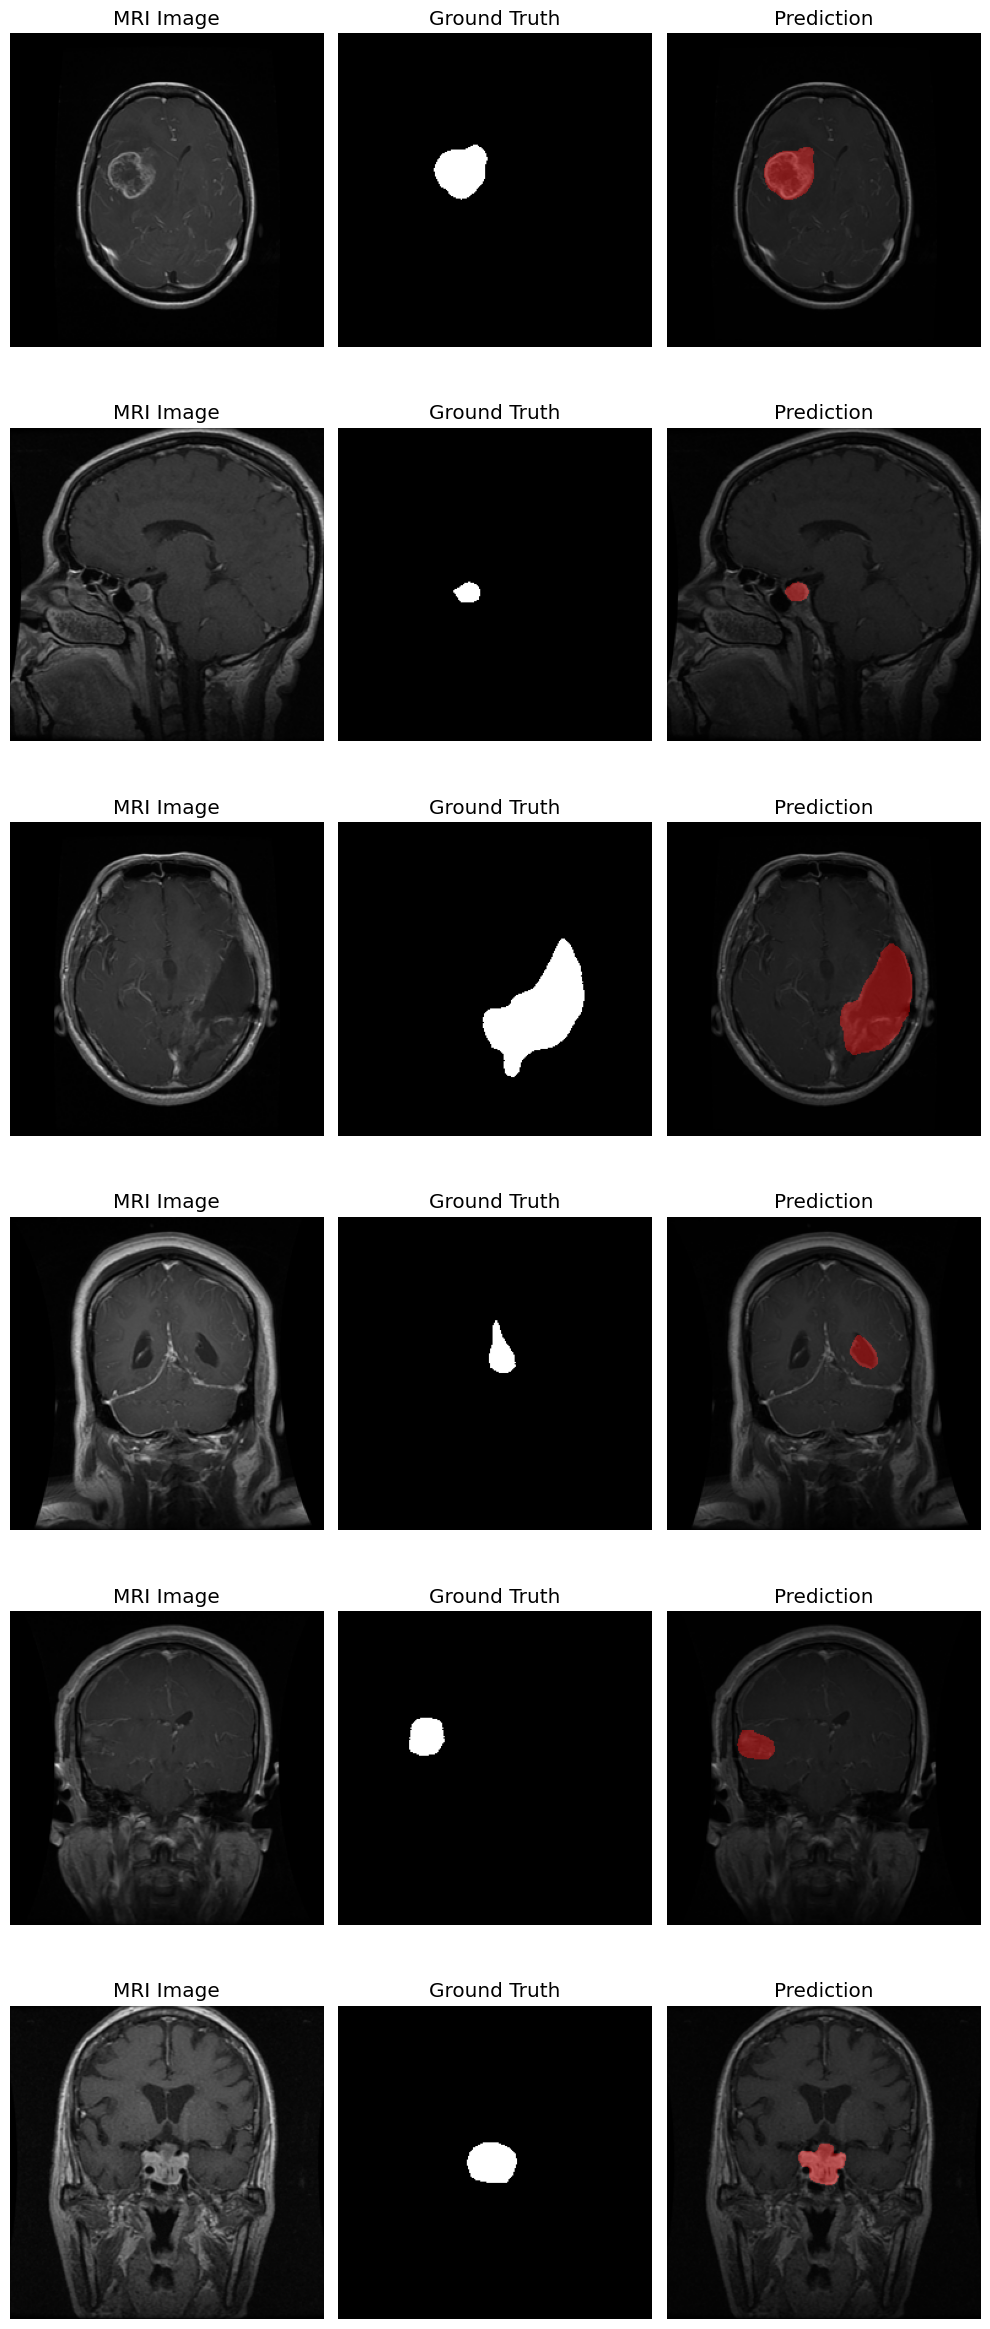

In [71]:
def overlay_mask_on_image(image, mask, alpha=0.4):
  img = image.copy()
  mask_color = np.zeros_like(img)
  mask_color[...,0] = (mask * 255).astype(np.uint8)
  overlay = cv2.addWeighted(img, 1-alpha, mask_color, alpha, 0)
  return overlay

model.eval()
n_show = 6
fig, axs = plt.subplots(n_show, 3, figsize=(10, 4*n_show))
for i in range(n_show):
  img_path = val_imgs[i]
  mask_path = val_masks[i]
  img_np = np.array(Image.open(img_path).convert("RGB").resize((256,256)))
  mask_np = np.array(Image.open(mask_path).convert("L").resize((256,256))) > 127
  input_t = valid_transform(image=img_np)["image"].unsqueeze(0).to(DEVICE)
  with torch.no_grad():
    pred = model(input_t)
    pred_prob = torch.sigmoid(pred).squeeze().cpu().numpy()
    pred_bin = pred_prob > 0.5

  overlay = overlay_mask_on_image(img_np, pred_bin)
  axs[i, 0].imshow(img_np); axs[i, 0].set_title("MRI Image"); axs[i, 0].axis("off")
  axs[i, 1].imshow(mask_np, cmap='gray'); axs[i, 1].set_title("Ground Truth"); axs[i, 1].axis("off")
  axs[i, 2].imshow(overlay); axs[i, 2].set_title("Prediction"); axs[i, 2].axis("off")

plt.tight_layout()
plt.show()

## 10. Extended Visualisation: Heatmaps and Contours

A more detailed view of predictions for 12 validation images, with four panels per row:

1. **Original MRI:** the input image.
2. **Ground Truth Mask:** the expert annotation.
3. **Prediction Probability (Heatmap):** the raw sigmoid output before thresholding. Bright areas are pixels the model is confident are tumour. Dimmer areas show uncertainty, often along tumour edges.
4. **Predicted Contours (green):** the outline of the thresholded prediction, found with `cv2.findContours` and drawn over the MRI. This makes the boundary easy to compare with the real tumour.

The heatmap shows *how confident* the model is, not just its final yes/no decision. That is useful for spotting borderline cases and explaining the model's behaviour in a report.

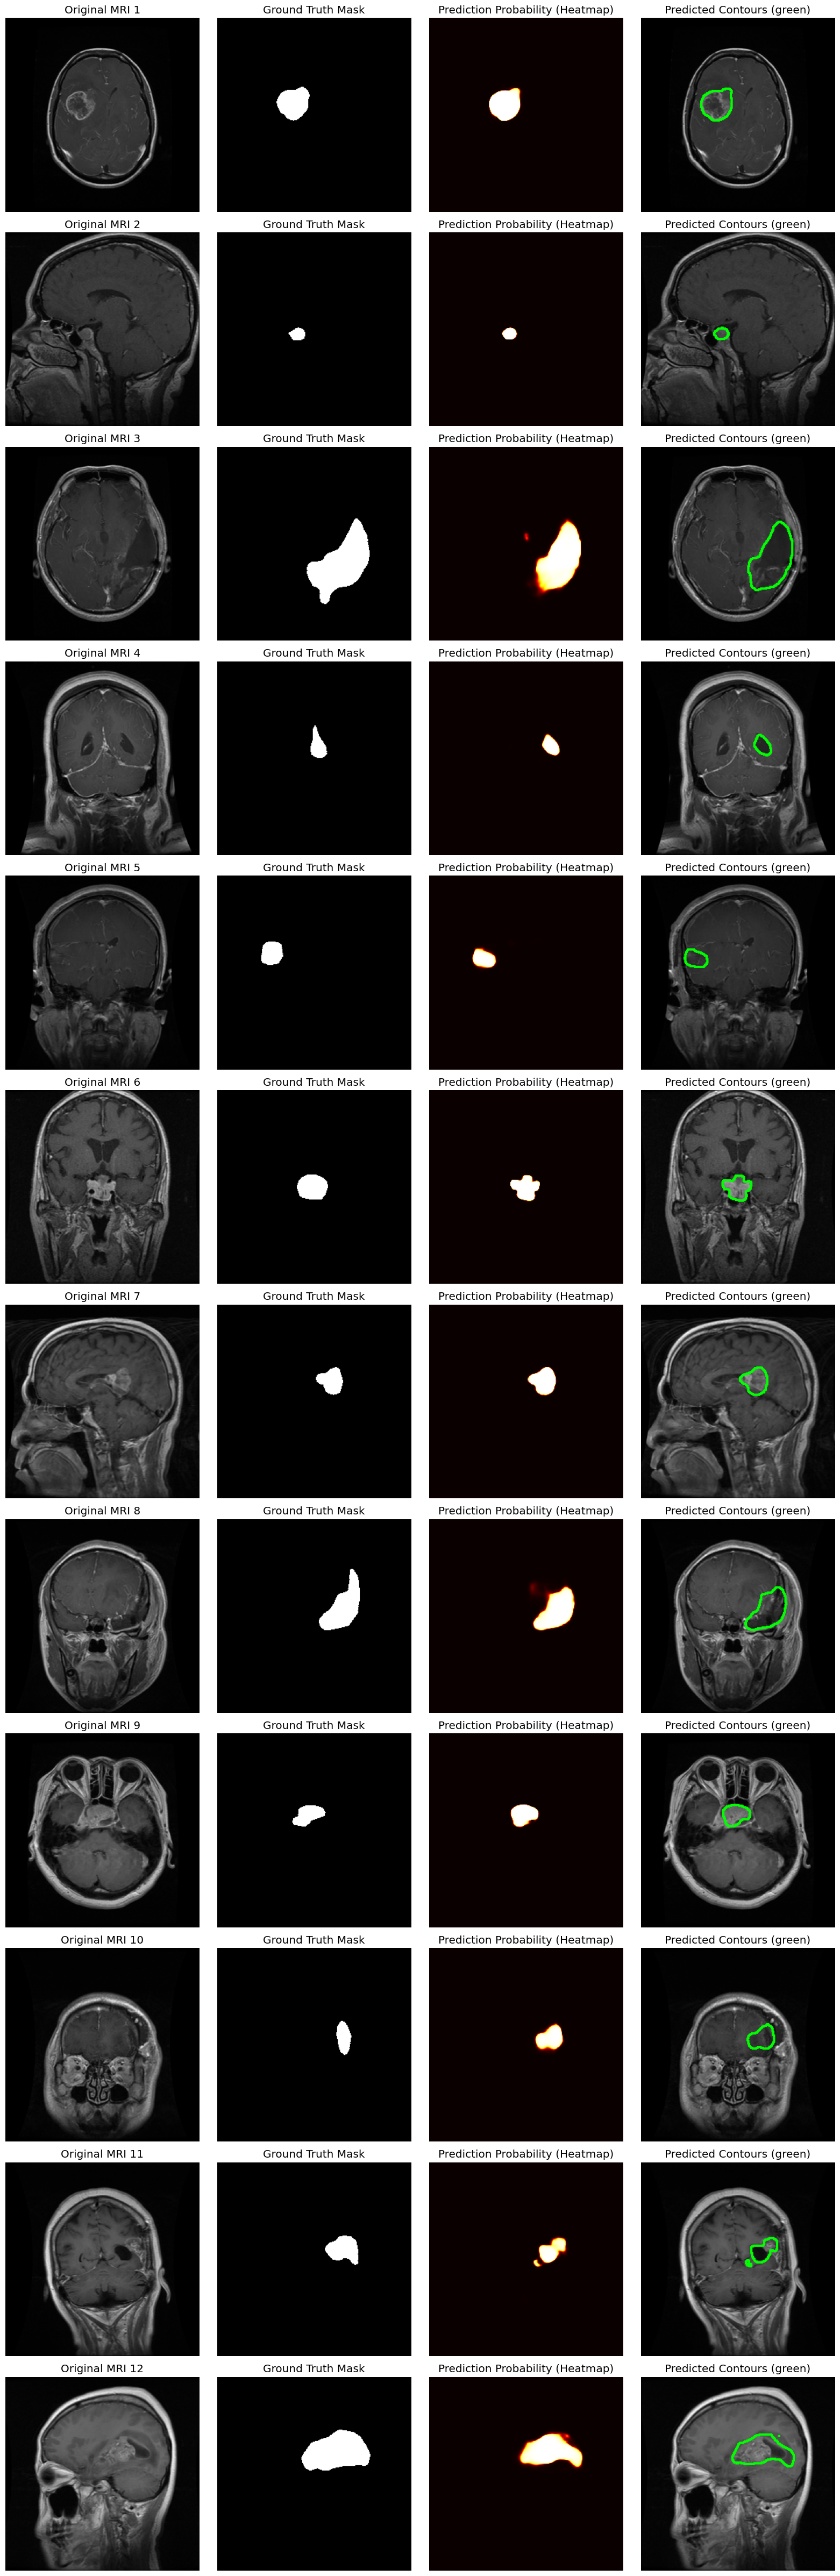

In [72]:
import matplotlib.patches as patches

def visualize_predictions(model, img_paths, mask_paths, n_samples=12):
    model.eval()
    fig, axs = plt.subplots(n_samples, 4, figsize=(16, 4*n_samples))

    for i in range(n_samples):
        img_path = img_paths[i]
        mask_path = mask_paths[i]

        img_np = np.array(Image.open(img_path).convert("RGB").resize((256,256)))
        mask_np = np.array(Image.open(mask_path).convert("L").resize((256,256))) > 127

        input_t = valid_transform(image=img_np)["image"].unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            pred = model(input_t)
            pred_prob = torch.sigmoid(pred).squeeze().cpu().numpy()
            pred_bin = pred_prob > 0.5

        overlay_pred = overlay_mask_on_image(img_np, pred_bin)

        contours, _ = cv2.findContours(pred_bin.astype("uint8"), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        contour_img = img_np.copy()
        cv2.drawContours(contour_img, contours, -1, (0,255,0), 2)

        axs[i,0].imshow(img_np)
        axs[i,0].set_title(f"Original MRI {i+1}")
        axs[i,0].axis("off")

        axs[i,1].imshow(mask_np, cmap="gray")
        axs[i,1].set_title("Ground Truth Mask")
        axs[i,1].axis("off")

        axs[i,2].imshow(pred_prob, cmap="hot")
        axs[i,2].set_title("Prediction Probability (Heatmap)")
        axs[i,2].axis("off")

        axs[i,3].imshow(contour_img)
        axs[i,3].set_title("Predicted Contours (green)")
        axs[i,3].axis("off")

    plt.tight_layout()
    plt.show()


visualize_predictions(model, val_imgs, val_masks, n_samples=12)